# U-Net → ResNet50 Sequential Pipeline
## LPF Method 1 + Stratified 5-Fold CV + External Held-Out Test

Pipeline:
**Raw image → fixed U-Net → binary mask → LPF calculation + background removal → masked image → ResNet50 → growth-stage prediction**

LPF is calculated and saved separately as a structural indicator. It is **not** fed directly into ResNet50.


In [1]:
!nvidia-smi


Wed Oct 14 06:59:07 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   59C    P8             14W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
import os

dataset_path = "/content/drive/MyDrive/tomato final dataset"

print("Dataset exists:", os.path.exists(dataset_path))

if os.path.exists(dataset_path):
    print("Contents:", os.listdir(dataset_path))


Dataset exists: True
Contents: ['README.roboflow.txt', 'README.dataset.txt', 'train', 'test', 'valid']


In [4]:
import os

dataset_path = "/content/drive/MyDrive/tomato final dataset"

if not os.path.exists(dataset_path):
    raise FileNotFoundError(
        f"Dataset not found: {dataset_path}"
    )

print("Dataset exists:", True)
print("\nMain contents:")
print(os.listdir(dataset_path))

for split in ["train", "valid", "test"]:
    split_path = os.path.join(dataset_path, split)

    print(f"\n===== {split.upper()} =====")

    if os.path.exists(split_path):
        print(os.listdir(split_path))
    else:
        raise FileNotFoundError(
            f"Missing split folder: {split_path}"
        )


Dataset exists: True

Main contents:
['README.roboflow.txt', 'README.dataset.txt', 'train', 'test', 'valid']

===== TRAIN =====
['_annotations.coco.json', 'seeding', 'fruiting', 'flowering', 'developing']

===== VALID =====
['_annotations.coco.json', 'seeding', 'fruiting', 'developing', 'flowering']

===== TEST =====
['_annotations.coco.json', 'seeding', 'flowering', 'developing', 'fruiting']


In [5]:
image_extensions = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
)

for split in ["train", "valid", "test"]:
    split_path = os.path.join(dataset_path, split)

    print(f"\n===== {split.upper()} IMAGE COUNTS =====")

    total = 0

    for class_name in sorted(os.listdir(split_path)):
        class_path = os.path.join(split_path, class_name)

        if os.path.isdir(class_path):
            count = len([
                f
                for f in os.listdir(class_path)
                if f.lower().endswith(image_extensions)
            ])

            print(f"{class_name}: {count}")
            total += count

    print("Total:", total)



===== TRAIN IMAGE COUNTS =====
developing: 142
flowering: 210
fruiting: 71
seeding: 264
Total: 687

===== VALID IMAGE COUNTS =====
developing: 20
flowering: 30
fruiting: 9
seeding: 76
Total: 135

===== TEST IMAGE COUNTS =====
developing: 41
flowering: 60
fruiting: 21
seeding: 38
Total: 160


In [6]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    raise RuntimeError(
        "GPU not detected. Select Runtime > Change runtime type > T4 GPU."
    )


PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [7]:
import os
import copy
import time
import random
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

from torchvision import transforms, models

from PIL import Image

from sklearn.model_selection import StratifiedKFold

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tqdm.auto import tqdm

print("Imports completed successfully")


Imports completed successfully


In [8]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


Device: cuda


In [9]:
DATASET_PATH = (
    "/content/drive/MyDrive/"
    "tomato final dataset"
)

TRAIN_DIR = os.path.join(DATASET_PATH, "train")
VALID_DIR = os.path.join(DATASET_PATH, "valid")
TEST_DIR = os.path.join(DATASET_PATH, "test")

CLASS_NAMES = [
    "developing",
    "flowering",
    "fruiting",
    "seeding"
]

NUM_CLASSES = len(CLASS_NAMES)

IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_EPOCHS = 20
LEARNING_RATE = 1e-4

NUM_WORKERS = 2

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]

PIPELINE_ROOT = (
    "/content/drive/MyDrive/"
    "tomato_research/"
    "unet_pipeline"
)

OUTPUT_DIR = os.path.join(
    PIPELINE_ROOT,
    "resnet50_5fold_cv"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

print(
    "Dataset exists:",
    os.path.exists(DATASET_PATH)
)

print(
    "Pipeline root:",
    PIPELINE_ROOT
)

print(
    "Output directory:",
    OUTPUT_DIR
)


Dataset exists: True
Pipeline root: /content/drive/MyDrive/tomato_research/unet_pipeline
Output directory: /content/drive/MyDrive/tomato_research/unet_pipeline/resnet50_5fold_cv


In [10]:
for split in ["train", "valid", "test"]:
    split_path = os.path.join(DATASET_PATH, split)

    print(f"\n===== {split.upper()} IMAGE COUNTS =====")

    total = 0

    for class_name in CLASS_NAMES:
        class_path = os.path.join(
            split_path,
            class_name
        )

        if not os.path.exists(class_path):
            raise FileNotFoundError(
                f"Missing class folder: {class_path}"
            )

        files = [
            f
            for f in os.listdir(class_path)
            if f.lower().endswith(image_extensions)
        ]

        print(f"{class_name}: {len(files)}")
        total += len(files)

    print("Total:", total)



===== TRAIN IMAGE COUNTS =====
developing: 142
flowering: 210
fruiting: 71
seeding: 264
Total: 687

===== VALID IMAGE COUNTS =====
developing: 20
flowering: 30
fruiting: 9
seeding: 76
Total: 135

===== TEST IMAGE COUNTS =====
developing: 41
flowering: 60
fruiting: 21
seeding: 38
Total: 160


In [11]:
UNET_CHECKPOINT = (
    "/content/drive/MyDrive/"
    "tomato_research/"
    "checkpoints/"
    "unet/"
    "final/"
    "unet_tomato_final.pth"
)

print("U-Net checkpoint path:")
print(UNET_CHECKPOINT)


U-Net checkpoint path:
/content/drive/MyDrive/tomato_research/checkpoints/unet/final/unet_tomato_final.pth


In [12]:
print(
    "U-Net checkpoint exists:",
    os.path.exists(UNET_CHECKPOINT)
)

if not os.path.exists(UNET_CHECKPOINT):
    raise FileNotFoundError(
        "U-Net checkpoint was not found.\n"
        f"Expected path:\n{UNET_CHECKPOINT}"
    )

print(
    "File size:",
    os.path.getsize(UNET_CHECKPOINT),
    "bytes"
)


U-Net checkpoint exists: True
File size: 31131802 bytes


In [13]:
class DoubleConv(nn.Module):

    def __init__(self, in_ch, out_ch):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_ch,
                out_ch,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_ch,
                out_ch,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):

    def __init__(self):
        super().__init__()

        self.enc1 = DoubleConv(3, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)
        self.enc4 = DoubleConv(128, 256)

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        self.bottleneck = DoubleConv(
            256,
            512
        )

        self.up4 = nn.ConvTranspose2d(
            512,
            256,
            kernel_size=2,
            stride=2
        )
        self.dec4 = DoubleConv(
            512,
            256
        )

        self.up3 = nn.ConvTranspose2d(
            256,
            128,
            kernel_size=2,
            stride=2
        )
        self.dec3 = DoubleConv(
            256,
            128
        )

        self.up2 = nn.ConvTranspose2d(
            128,
            64,
            kernel_size=2,
            stride=2
        )
        self.dec2 = DoubleConv(
            128,
            64
        )

        self.up1 = nn.ConvTranspose2d(
            64,
            32,
            kernel_size=2,
            stride=2
        )
        self.dec1 = DoubleConv(
            64,
            32
        )

        self.out_conv = nn.Conv2d(
            32,
            1,
            kernel_size=1
        )

    def forward(self, x):
        e1 = self.enc1(x)

        e2 = self.enc2(
            self.pool(e1)
        )

        e3 = self.enc3(
            self.pool(e2)
        )

        e4 = self.enc4(
            self.pool(e3)
        )

        b = self.bottleneck(
            self.pool(e4)
        )

        d4 = self.up4(b)
        d4 = torch.cat(
            [d4, e4],
            dim=1
        )
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat(
            [d3, e3],
            dim=1
        )
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat(
            [d2, e2],
            dim=1
        )
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat(
            [d1, e1],
            dim=1
        )
        d1 = self.dec1(d1)

        return self.out_conv(d1)


print(
    "U-Net architecture defined successfully"
)


U-Net architecture defined successfully


In [14]:
checkpoint = torch.load(
    UNET_CHECKPOINT,
    map_location=device,
    weights_only=True
)

if (
    isinstance(checkpoint, dict)
    and "model_state_dict" in checkpoint
):
    state_dict = checkpoint[
        "model_state_dict"
    ]

elif (
    isinstance(checkpoint, dict)
    and "state_dict" in checkpoint
):
    state_dict = checkpoint[
        "state_dict"
    ]

else:
    state_dict = checkpoint


clean_state_dict = {}

for key, value in state_dict.items():

    if key.startswith("module."):
        new_key = key[
            len("module.") :
        ]
    else:
        new_key = key

    clean_state_dict[
        new_key
    ] = value


state_dict = clean_state_dict


unet_model = UNet().to(
    device
)


unet_model.load_state_dict(
    state_dict,
    strict=True
)


unet_model.eval()


for parameter in (
    unet_model.parameters()
):
    parameter.requires_grad = False


total_params = sum(
    p.numel()
    for p in unet_model.parameters()
)


print(
    "U-Net loaded successfully"
)

print(
    "Total U-Net parameters:",
    total_params
)


U-Net loaded successfully
Total U-Net parameters: 7765985


In [15]:
crop_transform = transforms.Compose([
    transforms.Resize(
        int(
            IMAGE_SIZE * 1.14
        )
    ),
    transforms.CenterCrop(
        IMAGE_SIZE
    )
])

to_tensor = transforms.ToTensor()

normalize = transforms.Normalize(
    IMAGENET_MEAN,
    IMAGENET_STD
)

UNET_THRESHOLD = 0.5

print(
    "U-Net preprocessing ready"
)

print(
    "Image size:",
    IMAGE_SIZE
)

print(
    "Mask threshold:",
    UNET_THRESHOLD
)


U-Net preprocessing ready
Image size: 224
Mask threshold: 0.5


In [16]:
@torch.no_grad()
def create_masked_image(
    image_path
):

    img = Image.open(
        image_path
    ).convert(
        "RGB"
    )

    img_crop = crop_transform(
        img
    )

    raw_tensor = to_tensor(
        img_crop
    )

    unet_input = normalize(
        raw_tensor
    ).unsqueeze(
        0
    ).to(
        device
    )

    logits = unet_model(
        unet_input
    )

    probabilities = torch.sigmoid(
        logits
    )

    mask = (
        probabilities
        >= UNET_THRESHOLD
    ).float()

    foreground_pixels = (
        mask.sum().item()
    )

    total_pixels = (
        mask.numel()
    )

    lpf = (
        foreground_pixels
        / total_pixels
    )

    masked_tensor = (
        raw_tensor
        .unsqueeze(0)
        .to(device)
        * mask
    ).squeeze(
        0
    ).cpu()

    return (
        img_crop,
        mask.squeeze().cpu(),
        masked_tensor,
        lpf
    )


In [17]:
developing_test_dir = os.path.join(
    TEST_DIR,
    "developing"
)

sample_files = sorted([
    f
    for f in os.listdir(
        developing_test_dir
    )
    if f.lower().endswith(
        image_extensions
    )
])

sample_path = os.path.join(
    developing_test_dir,
    sample_files[0]
)

(
    original_img,
    predicted_mask,
    masked_img,
    sample_lpf
) = create_masked_image(
    sample_path
)

print(
    "Sample:",
    sample_path
)

print(
    "Original size:",
    original_img.size
)

print(
    "Mask shape:",
    predicted_mask.shape
)

print(
    "Unique mask values:",
    torch.unique(
        predicted_mask
    ).tolist()
)

print(
    "LPF:",
    round(
        sample_lpf,
        4
    )
)

print(
    "LPF percentage:",
    round(
        sample_lpf * 100,
        2
    ),
    "%"
)


Sample: /content/drive/MyDrive/tomato final dataset/test/developing/photo_dev (103)_jpg.rf.RWQrfFCEy7p25IXgGCmv.jpg
Original size: (224, 224)
Mask shape: torch.Size([224, 224])
Unique mask values: [0.0, 1.0]
LPF: 0.4807
LPF percentage: 48.07 %


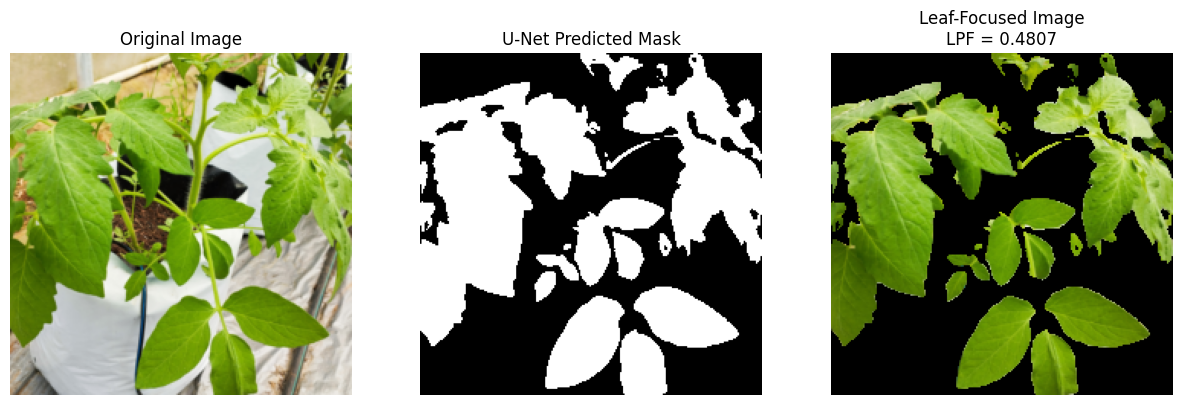

In [18]:
plt.figure(
    figsize=(15, 5)
)

plt.subplot(
    1,
    3,
    1
)

plt.imshow(
    original_img
)

plt.title(
    "Original Image"
)

plt.axis(
    "off"
)

plt.subplot(
    1,
    3,
    2
)

plt.imshow(
    predicted_mask,
    cmap="gray"
)

plt.title(
    "U-Net Predicted Mask"
)

plt.axis(
    "off"
)

plt.subplot(
    1,
    3,
    3
)

plt.imshow(
    masked_img.permute(
        1,
        2,
        0
    )
)

plt.title(
    f"Leaf-Focused Image\n"
    f"LPF = {sample_lpf:.4f}"
)

plt.axis(
    "off"
)

plt.show()


In [19]:
LOCAL_MASKED_DIR = (
    "/content/"
    "data_unet_masked_resnet50"
)

os.makedirs(
    LOCAL_MASKED_DIR,
    exist_ok=True
)

print(
    "U-Net masked dataset "
    "will be stored at:"
)

print(
    LOCAL_MASKED_DIR
)


U-Net masked dataset will be stored at:
/content/data_unet_masked_resnet50


In [20]:
@torch.no_grad()
def mask_and_save(
    src_path,
    dst_path
):

    img = Image.open(
        src_path
    ).convert(
        "RGB"
    )

    img_crop = crop_transform(
        img
    )

    raw01 = to_tensor(
        img_crop
    )

    unet_input = normalize(
        raw01
    ).unsqueeze(
        0
    ).to(
        device
    )

    logits = unet_model(
        unet_input
    )

    probabilities = torch.sigmoid(
        logits
    )

    pred_mask = (
        probabilities
        >= UNET_THRESHOLD
    ).float()

    foreground_pixels = (
        pred_mask
        .sum()
        .item()
    )

    total_pixels = (
        pred_mask
        .numel()
    )

    lpf = (
        foreground_pixels
        / total_pixels
    )

    masked = (
        raw01
        .unsqueeze(0)
        .to(device)
        * pred_mask
    ).squeeze(
        0
    ).cpu()

    masked_img = (
        transforms
        .ToPILImage()(
            masked
        )
    )

    os.makedirs(
        os.path.dirname(
            dst_path
        ),
        exist_ok=True
    )

    masked_img.save(
        dst_path,
        quality=95
    )

    return lpf


In [21]:
SPLITS = [
    "train",
    "valid",
    "test"
]

n_done = 0
lpf_records = []


for split in SPLITS:

    print(
        f"\nProcessing {split.upper()}..."
    )

    for stage in CLASS_NAMES:

        src_dir = os.path.join(
            DATASET_PATH,
            split,
            stage
        )

        dst_dir = os.path.join(
            LOCAL_MASKED_DIR,
            split,
            stage
        )

        os.makedirs(
            dst_dir,
            exist_ok=True
        )

        filenames = [
            f
            for f in sorted(
                os.listdir(
                    src_dir
                )
            )
            if f.lower().endswith(
                image_extensions
            )
        ]

        for fname in tqdm(
            filenames,
            desc=f"{split}/{stage}"
        ):

            src_path = os.path.join(
                src_dir,
                fname
            )

            dst_path = os.path.join(
                dst_dir,
                fname
            )

            lpf = mask_and_save(
                src_path,
                dst_path
            )

            lpf_records.append({
                "image": fname,
                "split": split,
                "stage": stage,
                "LPF": lpf,
                "LPF_percent": lpf * 100
            })

            n_done += 1


print(
    "\nCompleted."
)

print(
    "Total U-Net masked images generated:",
    n_done
)


lpf_df = pd.DataFrame(
    lpf_records
)


LPF_CSV_PATH = os.path.join(
    OUTPUT_DIR,
    "unet_resnet50_lpf_values.csv"
)


lpf_df.to_csv(
    LPF_CSV_PATH,
    index=False
)


print(
    "\nLPF values saved to:"
)

print(
    LPF_CSV_PATH
)


display(
    lpf_df.head()
)



Processing TRAIN...


train/developing:   0%|          | 0/142 [00:00<?, ?it/s]

train/flowering:   0%|          | 0/210 [00:00<?, ?it/s]

train/fruiting:   0%|          | 0/71 [00:00<?, ?it/s]

train/seeding:   0%|          | 0/264 [00:00<?, ?it/s]

...

test/flowering:   0%|          | 0/60 [00:00<?, ?it/s]

test/fruiting:   0%|          | 0/21 [00:00<?, ?it/s]

test/seeding:   0%|          | 0/38 [00:00<?, ?it/s]


Completed.
Total U-Net masked images generated: 982

LPF values saved to:
/content/drive/MyDrive/tomato_research/unet_pipeline/resnet50_5fold_cv/unet_resnet50_lpf_values.csv


,image,split,stage,LPF,LPF_percent
0,photo_dev (1)_jpg.rf.sUf4QjGbVQOtVEYcpDdQ.jpg,train,developing,0.324597,32.459742
1,photo_dev (100)_jpg.rf.RNqLRQIHCuBC2oZtVEel.jpg,train,developing,0.413305,41.330517
2,photo_dev (101)_jpg.rf.eSiKk2GlXqRFY6Oa9neE.jpg,train,developing,0.301359,30.135922
3,photo_dev (102)_jpg.rf.pMCmIOLoDI2I3cRd2kvu.jpg,train,developing,0.262974,26.297433
4,photo_dev (104)_jpg.rf.lMh1PECQE9VPBYX3M6bH.jpg,train,developing,0.436244,43.624442


In [22]:
stage_lpf_summary = (
    lpf_df
    .groupby(
        "stage"
    )[
        "LPF"
    ]
    .agg([
        "count",
        "mean",
        "std",
        "min",
        "max"
    ])
    .reset_index()
)

stage_lpf_summary[
    "mean_percent"
] = (
    stage_lpf_summary[
        "mean"
    ]
    * 100
)

stage_lpf_summary[
    "std_percent"
] = (
    stage_lpf_summary[
        "std"
    ]
    * 100
)

print(
    "Stage-wise LPF summary"
)

display(
    stage_lpf_summary
)

LPF_SUMMARY_PATH = os.path.join(
    OUTPUT_DIR,
    "unet_resnet50_lpf_stage_summary.csv"
)

stage_lpf_summary.to_csv(
    LPF_SUMMARY_PATH,
    index=False
)

print(
    "LPF summary saved to:"
)

print(
    LPF_SUMMARY_PATH
)


Stage-wise LPF summary


,stage,count,mean,std,min,max,mean_percent,std_percent
0,developing,203,0.306269,0.094115,0.031928,0.499043,30.626854,9.411475
1,flowering,300,0.273223,0.074775,0.099868,0.475965,27.322286,7.477476
2,fruiting,101,0.210474,0.055100,0.020069,0.337751,21.047359,5.509970
3,seeding,378,0.051809,0.032775,0.009307,0.255261,5.180943,3.277469


LPF summary saved to:
/content/drive/MyDrive/tomato_research/unet_pipeline/resnet50_5fold_cv/unet_resnet50_lpf_stage_summary.csv


In [23]:
masked_counts = {}

for split in ["train", "valid", "test"]:

    print(
        f"\n===== "
        f"{split.upper()} "
        f"MASKED IMAGE COUNTS ====="
    )

    total = 0

    for class_name in CLASS_NAMES:

        class_path = os.path.join(
            LOCAL_MASKED_DIR,
            split,
            class_name
        )

        files = [
            f
            for f in os.listdir(
                class_path
            )
            if f.lower().endswith(
                image_extensions
            )
        ]

        count = len(files)

        print(
            f"{class_name}: {count}"
        )

        total += count

    masked_counts[
        split
    ] = total

    print(
        "Total:",
        total
    )


assert masked_counts["train"] == 687
assert masked_counts["valid"] == 135
assert masked_counts["test"] == 160

print(
    "\nAll masked-image counts are correct."
)



===== TRAIN MASKED IMAGE COUNTS =====
developing: 142
flowering: 210
fruiting: 71
seeding: 264
Total: 687

===== VALID MASKED IMAGE COUNTS =====
developing: 20
flowering: 30
fruiting: 9
seeding: 76
Total: 135

===== TEST MASKED IMAGE COUNTS =====
developing: 41
flowering: 60
fruiting: 21
seeding: 38
Total: 160

All masked-image counts are correct.


In [24]:
class_to_idx = {
    class_name: idx
    for idx, class_name
    in enumerate(
        CLASS_NAMES
    )
}

print(
    class_to_idx
)


{'developing': 0, 'flowering': 1, 'fruiting': 2, 'seeding': 3}


In [25]:
cv_samples = []
cv_labels = []


for split in [
    "train",
    "valid"
]:

    for class_name in CLASS_NAMES:

        class_dir = os.path.join(
            LOCAL_MASKED_DIR,
            split,
            class_name
        )

        files = [
            f
            for f in sorted(
                os.listdir(
                    class_dir
                )
            )
            if f.lower().endswith(
                image_extensions
            )
        ]

        for fname in files:

            path = os.path.join(
                class_dir,
                fname
            )

            cv_samples.append(
                path
            )

            cv_labels.append(
                class_to_idx[
                    class_name
                ]
            )


cv_samples = np.array(
    cv_samples
)

cv_labels = np.array(
    cv_labels
)

print(
    "Total CV images:",
    len(
        cv_samples
    )
)

print(
    "Total CV labels:",
    len(
        cv_labels
    )
)

assert len(
    cv_samples
) == 822

assert len(
    cv_labels
) == 822


Total CV images: 822
Total CV labels: 822


In [26]:
for class_name, idx in (
    class_to_idx.items()
):

    count = np.sum(
        cv_labels == idx
    )

    print(
        f"{class_name}: {count}"
    )


developing: 162
flowering: 240
fruiting: 80
seeding: 340


In [27]:
test_samples = []
test_labels = []


for class_name in CLASS_NAMES:

    class_dir = os.path.join(
        LOCAL_MASKED_DIR,
        "test",
        class_name
    )

    files = [
        f
        for f in sorted(
            os.listdir(
                class_dir
            )
        )
        if f.lower().endswith(
            image_extensions
        )
    ]

    for fname in files:

        test_samples.append(
            os.path.join(
                class_dir,
                fname
            )
        )

        test_labels.append(
            class_to_idx[
                class_name
            ]
        )


test_samples = np.array(
    test_samples
)

test_labels = np.array(
    test_labels
)

print(
    "Held-out masked test images:",
    len(
        test_samples
    )
)

assert len(
    test_samples
) == 160


Held-out masked test images: 160


In [28]:
train_transform = transforms.Compose([

    transforms.RandomResizedCrop(
        IMAGE_SIZE,
        scale=(0.8, 1.0)
    ),

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(
        15
    ),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    )
])


eval_transform = transforms.Compose([

    transforms.Resize(
        int(
            IMAGE_SIZE * 1.14
        )
    ),

    transforms.CenterCrop(
        IMAGE_SIZE
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    )
])


print(
    "Classifier transforms ready"
)


Classifier transforms ready


In [29]:
class TomatoMaskedDataset(
    Dataset
):

    def __init__(
        self,
        paths,
        labels,
        transform=None
    ):

        self.paths = list(
            paths
        )

        self.labels = list(
            labels
        )

        self.transform = (
            transform
        )

    def __len__(
        self
    ):

        return len(
            self.paths
        )

    def __getitem__(
        self,
        idx
    ):

        image_path = (
            self.paths[
                idx
            ]
        )

        image = Image.open(
            image_path
        ).convert(
            "RGB"
        )

        label = int(
            self.labels[
                idx
            ]
        )

        if self.transform:
            image = (
                self.transform(
                    image
                )
            )

        return (
            image,
            label
        )


In [30]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

fold_splits = list(
    skf.split(
        cv_samples,
        cv_labels
    )
)

print(
    "Number of folds:",
    len(
        fold_splits
    )
)


Number of folds: 5


In [31]:
for fold, (
    train_idx,
    val_idx
) in enumerate(
    fold_splits,
    start=1
):

    print(
        f"\nFold {fold}: "
        f"Train = {len(train_idx)}, "
        f"Validation = {len(val_idx)}"
    )

    print(
        "Validation class counts:"
    )

    for class_name, class_idx in (
        class_to_idx.items()
    ):

        count = np.sum(
            cv_labels[
                val_idx
            ] == class_idx
        )

        print(
            f"  {class_name}: {count}"
        )



Fold 1: Train = 657, Validation = 165
Validation class counts:
  developing: 33
  flowering: 48
  fruiting: 16
  seeding: 68

Fold 2: Train = 657, Validation = 165
Validation class counts:
  developing: 33
  flowering: 48
  fruiting: 16
  seeding: 68

Fold 3: Train = 658, Validation = 164
Validation class counts:
  developing: 32
  flowering: 48
  fruiting: 16
  seeding: 68

Fold 4: Train = 658, Validation = 164
Validation class counts:
  developing: 32
  flowering: 48
  fruiting: 16
  seeding: 68

Fold 5: Train = 658, Validation = 164
Validation class counts:
  developing: 32
  flowering: 48
  fruiting: 16
  seeding: 68


In [32]:
raw_test_samples = []
raw_test_labels = []


for class_name in CLASS_NAMES:

    class_dir = os.path.join(
        DATASET_PATH,
        "test",
        class_name
    )

    files = [
        f
        for f in sorted(
            os.listdir(
                class_dir
            )
        )
        if f.lower().endswith(
            image_extensions
        )
    ]

    for fname in files:

        raw_test_samples.append(
            os.path.join(
                class_dir,
                fname
            )
        )

        raw_test_labels.append(
            class_to_idx[
                class_name
            ]
        )


raw_test_samples = np.array(
    raw_test_samples
)

raw_test_labels = np.array(
    raw_test_labels
)

print(
    "Raw test images:",
    len(
        raw_test_samples
    )
)

assert len(
    raw_test_samples
) == 160


Raw test images: 160


In [33]:
def build_resnet50():

    model = models.resnet50(
        weights=(
            models
            .ResNet50_Weights
            .IMAGENET1K_V2
        )
    )

    model.fc = nn.Linear(
        model.fc.in_features,
        NUM_CLASSES
    )

    return model.to(
        device
    )


In [34]:
temp_model = build_resnet50()

print(
    "ResNet50 created successfully"
)

print(
    "Final layer:",
    temp_model.fc
)

del temp_model

torch.cuda.empty_cache()


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 154MB/s]


ResNet50 created successfully
Final layer: Linear(in_features=2048, out_features=4, bias=True)


In [35]:
def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer
):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(
        loader,
        leave=False
    ):

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad()

        outputs = model(
            images
        )

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += (
            loss.item()
            * images.size(0)
        )

        preds = outputs.argmax(
            dim=1
        )

        correct += (
            preds == labels
        ).sum().item()

        total += labels.size(
            0
        )

    epoch_loss = (
        running_loss
        / total
    )

    epoch_acc = (
        correct
        / total
    )

    return (
        epoch_loss,
        epoch_acc
    )


In [36]:
@torch.no_grad()
def evaluate_classifier(
    model,
    loader,
    criterion
):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_labels = []
    all_preds = []

    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        outputs = model(
            images
        )

        loss = criterion(
            outputs,
            labels
        )

        running_loss += (
            loss.item()
            * images.size(0)
        )

        preds = outputs.argmax(
            dim=1
        )

        correct += (
            preds == labels
        ).sum().item()

        total += labels.size(
            0
        )

        all_labels.extend(
            labels
            .cpu()
            .numpy()
        )

        all_preds.extend(
            preds
            .cpu()
            .numpy()
        )

    epoch_loss = (
        running_loss
        / total
    )

    epoch_acc = (
        correct
        / total
    )

    return (
        epoch_loss,
        epoch_acc,
        np.array(
            all_labels
        ),
        np.array(
            all_preds
        )
    )


In [37]:
@torch.no_grad()
def pipeline_predict(
    model,
    image_path
):

    img = Image.open(
        image_path
    ).convert(
        "RGB"
    )

    img_crop = crop_transform(
        img
    )

    raw01 = to_tensor(
        img_crop
    )

    unet_input = normalize(
        raw01
    ).unsqueeze(
        0
    ).to(
        device
    )

    segmentation_logits = unet_model(
        unet_input
    )

    probabilities = torch.sigmoid(
        segmentation_logits
    )

    pred_mask = (
        probabilities
        >= UNET_THRESHOLD
    ).float()

    masked_raw = (
        raw01
        .unsqueeze(0)
        .to(device)
        * pred_mask
    )

    masked_normalized = normalize(
        masked_raw.squeeze(
            0
        )
    ).unsqueeze(
        0
    )

    classification_logits = model(
        masked_normalized
    )

    pred = (
        classification_logits
        .argmax(
            dim=1
        )
        .item()
    )

    return pred


In [38]:
@torch.no_grad()
def evaluate_full_pipeline(
    model,
    image_paths,
    true_labels
):

    model.eval()
    unet_model.eval()

    predictions = []

    for image_path in tqdm(
        image_paths,
        desc=(
            "RAW → U-Net "
            "→ ResNet50 test"
        ),
        leave=False
    ):

        pred = pipeline_predict(
            model,
            image_path
        )

        predictions.append(
            pred
        )

    predictions = np.array(
        predictions
    )

    true_labels = np.array(
        true_labels
    )

    accuracy = accuracy_score(
        true_labels,
        predictions
    )

    precision = precision_score(
        true_labels,
        predictions,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        true_labels,
        predictions,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        true_labels,
        predictions,
        average="macro",
        zero_division=0
    )

    cm = confusion_matrix(
        true_labels,
        predictions,
        labels=list(
            range(
                NUM_CLASSES
            )
        )
    )

    report = classification_report(
        true_labels,
        predictions,
        labels=list(
            range(
                NUM_CLASSES
            )
        ),
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "confusion_matrix": cm,
        "predictions": predictions,
        "report": report
    }


In [39]:
CHECKPOINT_DIR = os.path.join(
    OUTPUT_DIR,
    "checkpoints"
)

RESULT_DIR = os.path.join(
    OUTPUT_DIR,
    "results"
)

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)

os.makedirs(
    RESULT_DIR,
    exist_ok=True
)

print(
    "Checkpoint folder:",
    CHECKPOINT_DIR
)

print(
    "Results folder:",
    RESULT_DIR
)


Checkpoint folder: /content/drive/MyDrive/tomato_research/unet_pipeline/resnet50_5fold_cv/checkpoints
Results folder: /content/drive/MyDrive/tomato_research/unet_pipeline/resnet50_5fold_cv/results


In [40]:
all_fold_results = []
all_histories = []

criterion = nn.CrossEntropyLoss()


for fold_number, (
    train_idx,
    val_idx
) in enumerate(
    fold_splits,
    start=1
):

    print(
        "\n" + "=" * 70
    )

    print(
        f"FOLD {fold_number}/5"
    )

    print(
        "=" * 70
    )

    train_dataset = TomatoMaskedDataset(
        cv_samples[
            train_idx
        ],
        cv_labels[
            train_idx
        ],
        transform=train_transform
    )

    val_dataset = TomatoMaskedDataset(
        cv_samples[
            val_idx
        ],
        cv_labels[
            val_idx
        ],
        transform=eval_transform
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True
    )

    print(
        "Train:",
        len(
            train_dataset
        ),
        "| Validation:",
        len(
            val_dataset
        )
    )

    model = build_resnet50()

    optimizer = optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    scheduler = (
        optim
        .lr_scheduler
        .ReduceLROnPlateau(
            optimizer,
            mode="min",
            factor=0.5,
            patience=2
        )
    )

    best_val_acc = -1.0
    best_epoch = 0
    best_state = None
    history = []

    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        (
            "unet_"
            "resnet50_"
            f"fold_{fold_number}_"
            "best.pth"
        )
    )

    for epoch in range(
        1,
        NUM_EPOCHS + 1
    ):

        start_time = (
            time.time()
        )

        (
            train_loss,
            train_acc
        ) = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer
        )

        (
            val_loss,
            val_acc,
            val_true,
            val_pred
        ) = evaluate_classifier(
            model,
            val_loader,
            criterion
        )

        scheduler.step(
            val_loss
        )

        elapsed = (
            time.time()
            - start_time
        )

        current_lr = (
            optimizer
            .param_groups[0][
                "lr"
            ]
        )

        print(
            f"Fold {fold_number} | "
            f"Epoch {epoch:02d}/{NUM_EPOCHS} | "
            f"Train Loss {train_loss:.4f} | "
            f"Train Acc {train_acc:.4f} | "
            f"Val Loss {val_loss:.4f} | "
            f"Val Acc {val_acc:.4f} | "
            f"LR {current_lr:.2e} | "
            f"{elapsed:.1f}s"
        )

        history.append({
            "fold": fold_number,
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "learning_rate": current_lr
        })

        if val_acc > best_val_acc:

            best_val_acc = val_acc
            best_epoch = epoch

            best_state = copy.deepcopy(
                model.state_dict()
            )

            torch.save(
                best_state,
                checkpoint_path
            )

            print(
                f"  ✓ Best model saved "
                f"(Val Acc: {best_val_acc:.4f})"
            )

    if best_state is None:
        raise RuntimeError(
            f"No best state found "
            f"for Fold {fold_number}"
        )

    best_state = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    model.load_state_dict(
        best_state
    )

    print(
        f"\nBest validation accuracy: "
        f"{best_val_acc:.4f} "
        f"(epoch {best_epoch})"
    )

    pipeline_result = evaluate_full_pipeline(
        model,
        raw_test_samples,
        raw_test_labels
    )

    fold_result = {
        "fold": fold_number,
        "best_epoch": best_epoch,
        "best_val_accuracy": best_val_acc,
        "pipeline_accuracy": pipeline_result[
            "accuracy"
        ],
        "macro_precision": pipeline_result[
            "precision"
        ],
        "macro_recall": pipeline_result[
            "recall"
        ],
        "macro_f1": pipeline_result[
            "f1"
        ]
    }

    all_fold_results.append(
        fold_result
    )

    all_histories.extend(
        history
    )

    np.save(
        os.path.join(
            RESULT_DIR,
            (
                f"fold_{fold_number}_"
                "confusion_matrix.npy"
            )
        ),
        pipeline_result[
            "confusion_matrix"
        ]
    )

    prediction_df = pd.DataFrame({
        "image": raw_test_samples,

        "true_label": [
            CLASS_NAMES[x]
            for x
            in raw_test_labels
        ],

        "predicted_label": [
            CLASS_NAMES[x]
            for x
            in pipeline_result[
                "predictions"
            ]
        ]
    })

    prediction_df.to_csv(
        os.path.join(
            RESULT_DIR,
            (
                f"fold_{fold_number}_"
                "predictions.csv"
            )
        ),
        index=False
    )

    print(
        "\nU-NET → RESNET50 "
        "PIPELINE TEST RESULTS"
    )

    print(
        f"Accuracy       : "
        f"{pipeline_result['accuracy'] * 100:.2f}%"
    )

    print(
        f"Macro Precision: "
        f"{pipeline_result['precision'] * 100:.2f}%"
    )

    print(
        f"Macro Recall   : "
        f"{pipeline_result['recall'] * 100:.2f}%"
    )

    print(
        f"Macro F1       : "
        f"{pipeline_result['f1'] * 100:.2f}%"
    )

    del model

    torch.cuda.empty_cache()



FOLD 1/5
Train: 657 | Validation: 165


  0%|          | 0/21 [00:00<?, ?it/s]

Fold 1 | Epoch 01/20 | Train Loss 0.9084 | Train Acc 0.7139 | Val Loss 0.4819 | Val Acc 0.8727 | LR 1.00e-04 | 10.6s
  ✓ Best model saved (Val Acc: 0.8727)


  0%|          | 0/21 [00:00<?, ?it/s]

Fold 1 | Epoch 02/20 | Train Loss 0.3970 | Train Acc 0.8493 | Val Loss 0.3107 | Val Acc 0.8909 | LR 1.00e-04 | 9.7s
  ✓ Best model saved (Val Acc: 0.8909)


...

Fold 5 | Epoch 19/20 | Train Loss 0.0621 | Train Acc 0.9863 | Val Loss 0.2800 | Val Acc 0.9024 | LR 6.25e-06 | 9.6s


  0%|          | 0/21 [00:00<?, ?it/s]

Fold 5 | Epoch 20/20 | Train Loss 0.0540 | Train Acc 0.9848 | Val Loss 0.2901 | Val Acc 0.8963 | LR 3.13e-06 | 9.5s

Best validation accuracy: 0.9329 (epoch 15)


RAW → U-Net → ResNet50 test:   0%|          | 0/160 [00:00<?, ?it/s]


U-NET → RESNET50 PIPELINE TEST RESULTS
Accuracy       : 91.88%
Macro Precision: 90.11%
Macro Recall   : 91.88%
Macro F1       : 90.75%


In [41]:
print(
    "all_fold_results exists:",
    "all_fold_results"
    in globals()
)

print(
    "all_histories exists:",
    "all_histories"
    in globals()
)

if (
    "all_fold_results"
    in globals()
):

    print(
        "Number of fold results:",
        len(
            all_fold_results
        )
    )


all_fold_results exists: True
all_histories exists: True
Number of fold results: 5


In [42]:
results_df = pd.DataFrame(
    all_fold_results
)

history_df = pd.DataFrame(
    all_histories
)

results_path = os.path.join(
    RESULT_DIR,
    "unet_resnet50_5fold_results.csv"
)

history_path = os.path.join(
    RESULT_DIR,
    "unet_resnet50_training_history.csv"
)

results_df.to_csv(
    results_path,
    index=False
)

history_df.to_csv(
    history_path,
    index=False
)

print(
    "U-Net + ResNet50 "
    "results saved successfully."
)

print(
    "Results:",
    results_path
)

print(
    "History:",
    history_path
)

display(
    results_df
)


U-Net + ResNet50 results saved successfully.
Results: /content/drive/MyDrive/tomato_research/unet_pipeline/resnet50_5fold_cv/results/unet_resnet50_5fold_results.csv
History: /content/drive/MyDrive/tomato_research/unet_pipeline/resnet50_5fold_cv/results/unet_resnet50_training_history.csv


,fold,best_epoch,best_val_accuracy,pipeline_accuracy,macro_precision,macro_recall,macro_f1
0,1,9,0.939394,0.84375,0.838433,0.884233,0.839944
1,2,11,0.933333,0.87500,0.868243,0.907012,0.872815
2,3,10,0.939024,0.88750,0.875786,0.899869,0.881976
3,4,7,0.914634,0.91250,0.904408,0.901045,0.901534
4,5,15,0.932927,0.91875,0.901147,0.918757,0.907462


In [43]:
metrics = [
    "pipeline_accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1"
]

summary_rows = []

print(
    "=" * 70
)

print(
    "U-NET → RESNET50 "
    "SEQUENTIAL PIPELINE"
)

print(
    "5-FOLD RESULTS"
)

print(
    "=" * 70
)


for metric in metrics:

    values = (
        results_df[
            metric
        ].values
        * 100
    )

    mean_value = np.mean(
        values
    )

    std_value = np.std(
        values,
        ddof=1
    )

    print(
        f"{metric:22s}: "
        f"{mean_value:.2f}% "
        f"± "
        f"{std_value:.2f}%"
    )

    summary_rows.append({
        "Metric": metric,
        "Mean (%)": mean_value,
        "SD (%)": std_value
    })


summary_df = pd.DataFrame(
    summary_rows
)

summary_path = os.path.join(
    RESULT_DIR,
    "unet_resnet50_5fold_summary.csv"
)

summary_df.to_csv(
    summary_path,
    index=False
)

print(
    "\nSummary saved to:"
)

print(
    summary_path
)

display(
    summary_df
)


U-NET → RESNET50 SEQUENTIAL PIPELINE
5-FOLD RESULTS
pipeline_accuracy     : 88.75% ± 3.03%
macro_precision       : 87.76% ± 2.69%
macro_recall          : 90.22% ± 1.25%
macro_f1              : 88.07% ± 2.68%

Summary saved to:
/content/drive/MyDrive/tomato_research/unet_pipeline/resnet50_5fold_cv/results/unet_resnet50_5fold_summary.csv


,Metric,Mean (%),SD (%)
0,pipeline_accuracy,88.750000,3.029800
1,macro_precision,87.760370,2.691664
2,macro_recall,90.218351,1.251860
3,macro_f1,88.074607,2.680970


In [44]:
fold_table = (
    results_df[
        [
            "fold",
            "best_epoch",
            "best_val_accuracy",
            "pipeline_accuracy",
            "macro_precision",
            "macro_recall",
            "macro_f1"
        ]
    ]
    .copy()
)

display(
    fold_table
)


,fold,best_epoch,best_val_accuracy,pipeline_accuracy,macro_precision,macro_recall,macro_f1
0,1,9,0.939394,0.84375,0.838433,0.884233,0.839944
1,2,11,0.933333,0.87500,0.868243,0.907012,0.872815
2,3,10,0.939024,0.88750,0.875786,0.899869,0.881976
3,4,7,0.914634,0.91250,0.904408,0.901045,0.901534
4,5,15,0.932927,0.91875,0.901147,0.918757,0.907462


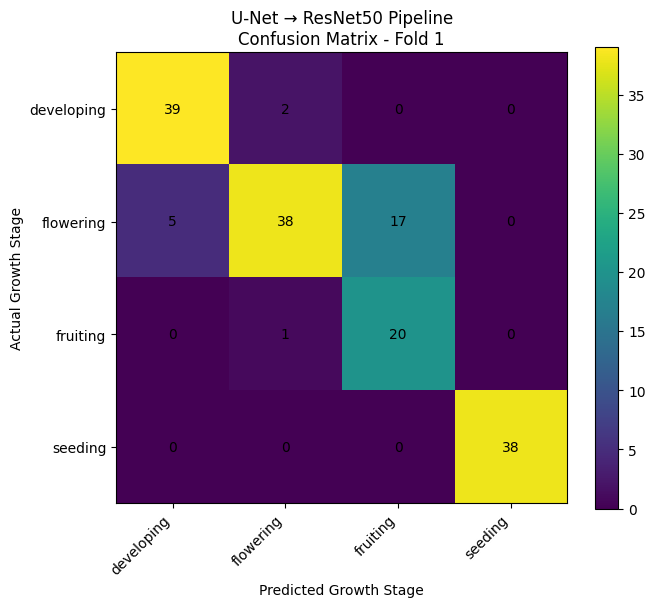

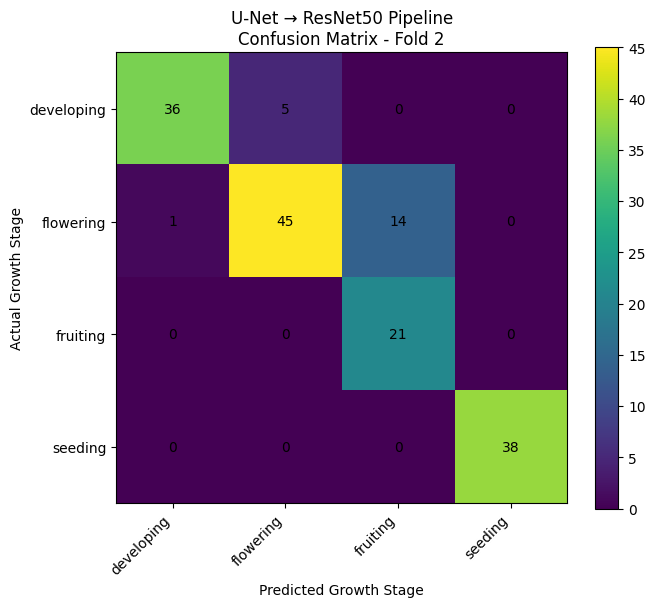

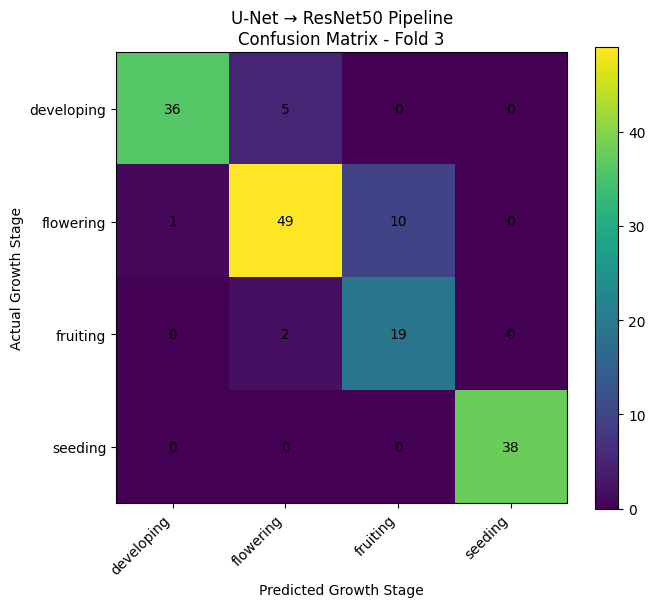

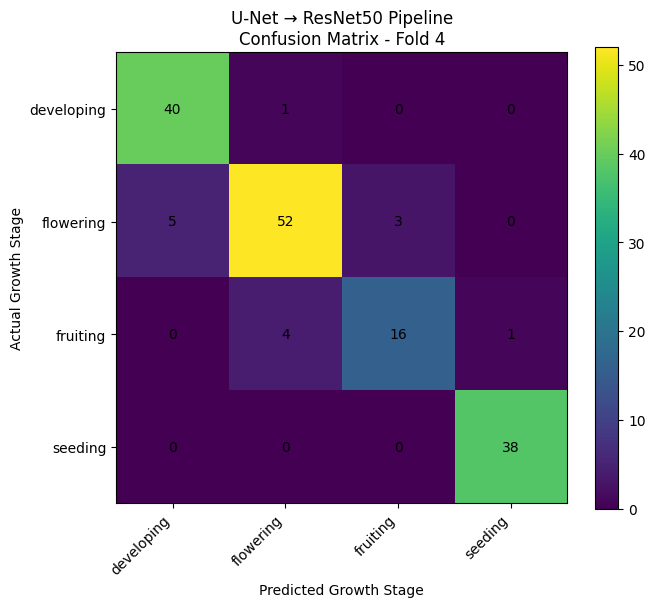

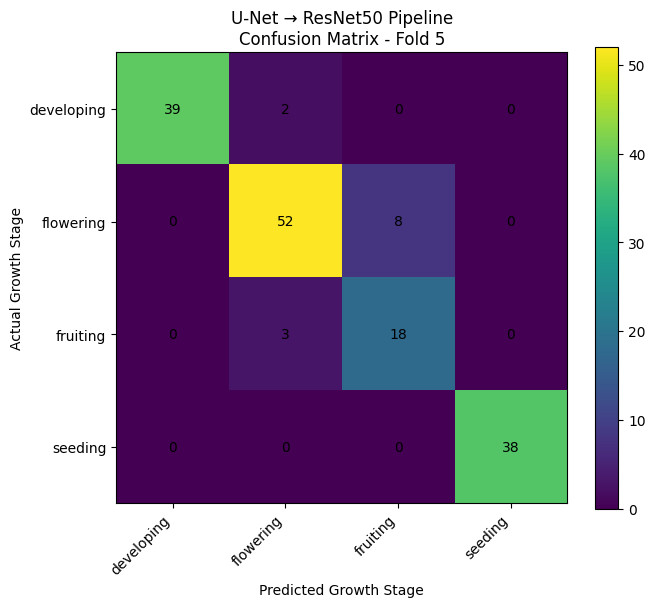

In [45]:
for fold_number in range(
    1,
    6
):

    cm_path = os.path.join(
        RESULT_DIR,
        (
            f"fold_{fold_number}_"
            "confusion_matrix.npy"
        )
    )

    cm = np.load(
        cm_path
    )

    fig, ax = plt.subplots(
        figsize=(7, 6)
    )

    im = ax.imshow(
        cm
    )

    ax.set_xticks(
        np.arange(
            len(
                CLASS_NAMES
            )
        )
    )

    ax.set_yticks(
        np.arange(
            len(
                CLASS_NAMES
            )
        )
    )

    ax.set_xticklabels(
        CLASS_NAMES,
        rotation=45,
        ha="right"
    )

    ax.set_yticklabels(
        CLASS_NAMES
    )

    ax.set_xlabel(
        "Predicted Growth Stage"
    )

    ax.set_ylabel(
        "Actual Growth Stage"
    )

    ax.set_title(
        (
            "U-Net → "
            "ResNet50 Pipeline\n"
            f"Confusion Matrix "
            f"- Fold {fold_number}"
        )
    )

    for i in range(
        cm.shape[0]
    ):

        for j in range(
            cm.shape[1]
        ):

            ax.text(
                j,
                i,
                str(
                    cm[
                        i,
                        j
                    ]
                ),
                ha="center",
                va="center"
            )

    fig.colorbar(
        im,
        ax=ax
    )

    plt.tight_layout()

    save_path = os.path.join(
        RESULT_DIR,
        (
            "unet_"
            "resnet50_"
            f"fold_{fold_number}_"
            "confusion_matrix.png"
        )
    )

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


In [46]:
print(
    "=" * 70
)

print(
    "U-NET + RESNET50 "
    "EXPERIMENT COMPLETED"
)

print(
    "=" * 70
)

print(
    "\nU-Net checkpoint:"
)

print(
    UNET_CHECKPOINT
)

print(
    "\nExperiment folder:"
)

print(
    OUTPUT_DIR
)

print(
    "\nResNet50 checkpoints:"
)

for file_name in sorted(
    os.listdir(
        CHECKPOINT_DIR
    )
):

    print(
        "-",
        file_name
    )

print(
    "\nResult files:"
)

for file_name in sorted(
    os.listdir(
        RESULT_DIR
    )
):

    print(
        "-",
        file_name
    )


U-NET + RESNET50 EXPERIMENT COMPLETED

U-Net checkpoint:
/content/drive/MyDrive/tomato_research/checkpoints/unet/final/unet_tomato_final.pth

Experiment folder:
/content/drive/MyDrive/tomato_research/unet_pipeline/resnet50_5fold_cv

ResNet50 checkpoints:
- unet_resnet50_fold_1_best.pth
- unet_resnet50_fold_2_best.pth
- unet_resnet50_fold_3_best.pth
- unet_resnet50_fold_4_best.pth
- unet_resnet50_fold_5_best.pth

Result files:
- fold_1_confusion_matrix.npy
- fold_1_predictions.csv
- fold_2_confusion_matrix.npy
- fold_2_predictions.csv
- fold_3_confusion_matrix.npy
- fold_3_predictions.csv
- fold_4_confusion_matrix.npy
- fold_4_predictions.csv
- fold_5_confusion_matrix.npy
- fold_5_predictions.csv
- unet_resnet50_5fold_results.csv
- unet_resnet50_5fold_summary.csv
- unet_resnet50_fold_1_confusion_matrix.png
- unet_resnet50_fold_2_confusion_matrix.png
- unet_resnet50_fold_3_confusion_matrix.png
- unet_resnet50_fold_4_confusion_matrix.png
- unet_resnet50_fold_5_confusion_matrix.png
- unet_